# data load

In [70]:
pip install --upgrade pip

Note: you may need to restart the kernel to use updated packages.


In [71]:
pip install -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


In [72]:
import osmnx as ox
import networkx as nx
import r5py
import json
import numpy as np
import pandas as pd
import geopandas as gpd
import shapely
import h3
import h3pandas
import pyrosm
import datetime

pd.set_option("display.max_columns", None)

In [ ]:
transport_modes=[r5py.TransportMode.WALK]
departure=datetime.datetime.now()
max_public_transport_rides=8
speed_walking=3.6,
departure_time_window=datetime.timedelta(minutes=10)
percentiles=[50]
max_time=datetime.timedelta(hours=2)
access_modes=[r5py.TransportMode.WALK]
egress_modes=None
snap_to_network=False
max_time_walking=None
max_time_cycling=None
max_time_driving=None
speed_cycling=12.0
max_bicycle_traffic_stress=3

## Definir parámetros

### 1. Archivo OSM

Se debe descargar el pbf de chile y guardarlo en la misma carpeta que este\
archivo `network_download.ipynb` con el siguiente comando
```bash
wget https://download.geofabrik.de/south-america/chile-latest.osm.pbf
```

o bien abriendo el mismo link en el navegador https://download.geofabrik.de/south-america/chile-latest.osm.pbf

IMPORTANTE: se debe renombrar como `chile-latest.osm.pbf` o especificar el nombre del archivo `osm_filename` en la siguiente celda

In [73]:
# archivo .pbf descargado desde la web de geofabrik
osm_filename = "chile-latest.osm.pbf"

### 2. Archivos GTFS

Se debe especificar los nombres de los archivos GTFS a incluir en la red,\
añadiendo cada nombre entre comillas en la siguiente lista

In [74]:
# archivos GTFS (.zip) a incluir en la red
gtfs = [
    "gtfs_14102026.zip",
    "gtfs_biotren_22102026.zip"
]

### 3. Area de estudio

Opciones:

1. Cargando archivo `.shp`, `.parquet`, `.kml`, `.gpkg` o `.json / .geojson`\
colocado en la misma carpeta donde está este archivo `accessibility_calculation.ipynb`

```python
    place_filename = "custom_polygon.shp"
```

In [75]:
# nombre de archivo a cargar (shapefile, parquet, geojson, kml, gpkg)

# place_filename = "mi_poligono.shp"
place_filename = ""

2. Con nombre del lugar\
(según nominatim https://nominatim.openstreetmap.org/ui/reverse.html?lat=-36.82381882597611&lon=-73.05084228515626&zoom=10)

```python
    place_name = "Concepción, Chile"
```

In [76]:
# selección de lugar (según nominatim)

# place_name = "Concepción, Chile"
place_name = "Concepción, Chile"

### 4. Puntos de interés

Opciones:

1. Se debe especificar en nombre del archivo de puntos de interés a considerar\
o bien, dejar vacío `pois_filename = ""` si no se cuenta con un archivo

In [77]:
pois_filename = ""

2. Describir las etiquetas a filtrar en los puntos de interés de OpenStreetMap

In [78]:
# etiquetas de Open Street Map para filtrar amenidades
tags = {
    "amenity": True,
    # add other keys like "shop": True if you want
    # also pick specific ones with "shop": ["supermarket", "books"]
}

### 5. Puntos de origen / Unidad de area

Se debe especificar la resolución de los hexágonos H3 Uber a generar\
en el area de estudio

In [79]:
# resolución de los hexágonos H3 Uber
h3_resolution = 10

### 6. Archivo de edificaciones

Opcionalmente, se puede especificar en nombre del archivo de edificaciones a\
considerar. Dejar vacío `buildings_filename = ""` si no se cuenta con un archivo

OBSERVACIÓN: se utiliza para hacer el cruce y decartar hexágonos sin viviendas en las manzanas censales

In [80]:
# nombre de archivo a cargar (shapefile, parquet, geojson, kml, gpkg)
buildings_filename = ""

### 7. Parámetros cálculo de tiempos de viaje

Se debe especificar los parámetros a especificar en el cálculo de las matrices\
de tiempos de viaje entre origenes y destinos

IMPORTANTE: está comentado el valor original para tener de referencia

In [81]:
# parámetros para el cálculo de la matriz de tiempos de viaje

# r5py.TransportMode.TRANSIT calcula tiempos de viaje usando todos los modos,
# pero si se especifican sólo algunos, estos serán usados a su vez

# transit modes to compute
# transport_modes=[r5py.TransportMode.TRANSIT],

# OBS: each element in this list will compute it's own travel time matrix,
# to consider multiple modes for a single matrix put them in a list (commented example in last item)
transport_modes=[
    r5py.TransportMode.WALK,
    # r5py.TransportMode.CAR,
    # r5py.TransportMode.TRANSIT,
    # [r5py.TransportMode.WALK, r5py.TransportMode.BUS]
]

# departure=datetime.datetime.now()
departure=datetime.datetime(2026, 10, 29, 7, 30, 0)

# --------------------
# ADVANCED PARAMETERS
# --------------------

# documentation on these parameters at https://r5py.readthedocs.io/v1.0.0/reference/reference.html#r5py.RegionalTask

# max_public_transport_rides=8
# speed_walking=3.6,
# departure_time_window=datetime.timedelta(minutes=10)
# percentiles=[50]
# max_time=datetime.timedelta(hours=2)

# access_modes=[r5py.TransportMode.WALK]

# por defecto tomar el mismo valor de access_modes
# egress_modes=None

# snap_to_network=False

# takes max_time if not provided
# max_time_walking=None

# takes max_time if not provided
# max_time_cycling=None

# takes max_time if not provided
# max_time_driving=None

# speed_cycling=12.0

# max_bicycle_traffic_stress=3

---

Área cargada con éxito: "Concepcion, Provincia de Concepción, Biobio Region, Chile"


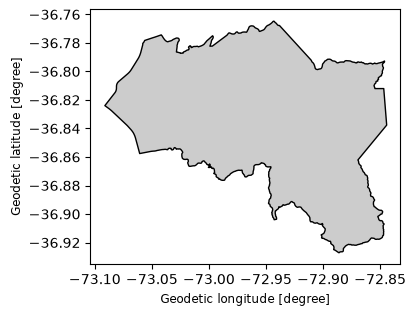

In [82]:
# load area of interest polygon

import os

if place_filename:
    try:
        parts = place_filename.split(".")
        file_extension = parts[-1].lower() if len(parts) > 1 else ""

        if file_extension in ["shp", "gpkg"]:
            area_gdf = gpd.read_file(place_filename)

        elif file_extension == "kml":
            area_gdf = gpd.read_file(place_filename, driver='KML')

        elif file_extension == "parquet":
            area_gdf = gpd.read_parquet(place_filename)

        elif file_extension in ["json", "geojson"]:
            with open(place_filename) as f:
                geojson = json.load(f)
            area_gdf = gpd.GeoDataFrame.from_features(geojson["features"], crs=4326)

        else:
            # raise an exception to avoid the next code that assigns a crs
            raise ValueError(f"ERROR: Se debe especificar un archivo con formato válido (.shp, .gpkg, .kml, .parquet, .json, .geojson)")

        # assign crs 4326 in case it hasn't
        if area_gdf.crs is None:
            area_gdf = area_gdf.set_crs(4326)
        elif area_gdf.crs != "EPSG:4326":
            area_gdf = area_gdf.to_crs(4326)

        area = area_gdf.geometry.union_all()
        area_gdf.plot(figsize=(4,4), color="#cccccc", edgecolor="black")
        print(f"Polígono \"{place_filename}\" cargado con éxito")

    except ValueError as e:
        print(e)

    except:
        print(f"ERROR: No se pudo abrir el archivo {place_filename}")

elif place_name:
    try:
        area_gdf = ox.geocode_to_gdf(place_name)
        area = area_gdf.geometry.union_all()
        area_gdf.plot(figsize=(4,4), color="#cccccc", edgecolor="black")
        print(f"Área cargada con éxito: \"{area_gdf.iloc[0].display_name}\"")
    except:
        print("ERROR: Nombre no reconocido")

else:
    print(f"ERROR: Se debe especificar un nombre de lugar o un archivo")

In [83]:
osm = pyrosm.OSM(osm_filename, bounding_box=area)

fp_clip = "tmp.osm.pbf"
osm.to_pbf(fp_clip)
osm = pyrosm.OSM(fp_clip, bounding_box=area)

Cropping chile-latest.osm.pbf:   0%|          | 0.00/350M [00:00<?, ?B/s]       

In [84]:
# load any file with geospatial data (.shp, .gpkg, .kml, .parquet, .json, .geojson)
import os

def load_any(filename):
    try:
        parts = filename.split(".")
        file_extension = parts[-1].lower() if len(parts) > 1 else ""

        if file_extension in ["shp", "gpkg"]:
            gdf = gpd.read_file(filename)

        elif file_extension == "kml":
            gdf = gpd.read_file(filename, driver='KML')

        elif file_extension == "parquet":
            gdf = gpd.read_parquet(filename)

        elif file_extension in ["json", "geojson"]:
            with open(filename) as f:
                geojson = json.load(f)
            gdf = gpd.GeoDataFrame.from_features(geojson["features"], crs=4326)

        else:
            # raise an exception to avoid the next code that assigns a crs
            raise ValueError(f"ERROR: Se debe especificar un archivo con formato válido (.shp, .gpkg, .kml, .parquet, .json, .geojson)")

        # assign crs 4326 in case it hasn't
        if gdf.crs is None:
            gdf = gdf.set_crs(4326)
        elif gdf.crs != "EPSG:4326":
            gdf = gdf.to_crs(4326)

        gdf.plot(figsize=(4,4), color="#cccccc", edgecolor="black")
        print(f"Archivo \"{filename}\" cargado con éxito")

    except ValueError as e:
        print(e)

    except:
        print(f"ERROR: No se pudo abrir el archivo {filename}")

In [85]:
# load blocks from census keeping the intersecting ones

blocks_gdf = gpd.read_parquet("blocks/Cartografia_censo2024_Pais_Manzanas.parquet")
match_indices = blocks_gdf.sindex.query([area], predicate="intersects")
blocks_gdf = blocks_gdf.iloc[match_indices[1]]

blocks_gdf = blocks_gdf[blocks_gdf.n_per > 0]

blocks_gdf = blocks_gdf.rename(columns={"SHAPE": "geometry"})
blocks_gdf = gpd.GeoDataFrame(blocks_gdf, geometry="geometry", crs=4326)

print(len(blocks_gdf))
blocks_gdf.head()

1676


,OBJECTID,CUT,COD_REGION,REGION,COD_PROVINCIA,PROVINCIA,COMUNA,AREA_C,MANZENT,DISTRITO,COD_DISTRITO,COD_LOCALIDAD,COD_ZONA,LOCALIDAD,COD_ENTIDAD,COD_MANZANA,ENTIDAD,TIPO_MZ,COD_CATEGORIA,CATEGORIA,MZ_BASE_CENSO,ID_ENTIDAD,ID_LOCALIDAD,ID_DISTRITO,ID_ZONA,n_per,n_hombres,n_mujeres,n_edad_0_5,n_edad_6_13,n_edad_14_17,n_edad_18_24,n_edad_25_44,n_edad_45_59,n_edad_60_mas,prom_edad,n_inmigrantes,n_nacionalidad,n_pueblos_orig,n_afrodescendencia,n_lengua_indigena,n_religion,n_dificultad_ver,n_dificultad_oir,n_dificultad_mover,n_dificultad_cogni,n_dificultad_cuidado,n_dificultad_comunic,n_discapacidad,n_estcivcon_casado,n_estcivcon_conviviente,n_estcivcon_conv_civil,n_estcivcon_anul_sep_div,n_estcivcon_viudo,n_estcivcon_soltero,prom_escolaridad18,n_asistencia_parv,n_asistencia_basica,n_asistencia_media,n_asistencia_superior,n_cine_nunca_curso_primera_infancia,n_cine_primaria,n_cine_secundaria,n_cine_terciaria_maestria_doctorado,n_cine_especial_diferencial,n_analfabet,n_ocupado,n_desocupado,n_fuera_fuerza_trabajo,n_cise_rec_independientes,n_cise_rec_dependientes,n_cise_rec_trabajador_no_remunerado,n_ciuo_1,n_ciuo_2,n_ciuo_3,n_ciuo_4,n_ciuo_5,n_ciuo_6,n_ciuo_7,n_ciuo_8,n_ciuo_9,n_ciuo_0,n_caenes_A,n_caenes_B,n_caenes_C,n_caenes_D,n_caenes_E,n_caenes_F,n_caenes_G,n_caenes_H,n_caenes_I,n_caenes_J,n_caenes_K,n_caenes_L,n_caenes_M,n_caenes_N,n_caenes_O,n_caenes_P,n_caenes_Q,n_caenes_R,n_caenes_S,n_caenes_T,n_caenes_U,n_transporte_auto,n_transporte_publico,n_transporte_camina,n_transporte_bicicleta,n_transporte_motocicleta,n_transporte_cab_lan_bote,n_transporte_otros,n_hog,prom_per_hog,n_hog_unipersonales,n_hog_60,n_hog_menores,n_jefatura_mujer,n_tenencia_propia_pagada,n_tenencia_propia_pagandose,n_tenencia_arrendada_contrato,n_tenencia_arrendada_sin_contrato,n_tenencia_cedida_trabajo,n_tenencia_cedida_familiar,n_tenencia_otro,n_comb_cocina_gas,n_comb_cocina_parafina,n_comb_cocina_lena,n_comb_cocina_pellet,n_comb_cocina_carbon,n_comb_cocina_electricidad,n_comb_cocina_solar,n_comb_cocina_no_utiliza,n_comb_calefaccion_gas,n_comb_calefaccion_parafina,n_comb_calefaccion_lena,n_comb_calefaccion_pellet,n_comb_calefaccion_carbon,n_comb_calefaccion_electricidad,n_comb_calefaccion_otra,n_comb_calefaccion_no_utiliza,n_serv_tel_movil,n_serv_compu,n_serv_tablet,n_serv_internet_fija,n_serv_internet_movil,n_serv_internet_satelital,n_internet,n_vp,n_vp_ocupada,n_vp_desocupada,n_tipo_viv_casa,n_tipo_viv_depto,n_tipo_viv_indigena,n_tipo_viv_pieza,n_tipo_viv_mediagua,n_tipo_viv_movil,n_tipo_viv_otro,n_dormitorios_1,n_dormitorios_2,n_dormitorios_3,n_dormitorios_4,n_dormitorios_5,n_dormitorios_6_o_mas,n_viv_hacinadas,n_viv_irrecuperables,n_hog_allegados,n_nucleos_hacinados_allegados,n_viv_no_ampliables,n_deficit_cuantitativo,n_mat_paredes_hormigon,n_mat_paredes_albanileria,n_mat_paredes_tabique_forrado,n_mat_paredes_tabique_sin_forro,n_mat_paredes_artesanal,n_mat_paredes_precarios,n_mat_techo_tejas,n_mat_techo_hormigon,n_mat_techo_zinc,n_mat_techo_fibrocemento,n_mat_techo_fonolita,n_mat_techo_paja,n_mat_techo_precarios,n_mat_techo_sin_cubierta,n_mat_piso_radier_con_revestimiento,n_mat_piso_radier_sin_revestimiento,n_mat_piso_baldosa_cemento,n_mat_piso_capa_cemento,n_mat_piso_tierra,n_fuente_agua_publica,n_fuente_agua_pozo,n_fuente_agua_camion,n_fuente_agua_rio,n_distrib_agua_llave,n_distrib_agua_llave_fuera,n_distrib_agua_acarreo,n_serv_hig_alc_dentro,n_serv_hig_alc_fuera,n_serv_hig_fosa,n_serv_hig_pozo,n_serv_hig_acequia_canal,n_serv_hig_cajon_otro,n_serv_hig_bano_quimico,n_serv_hig_bano_seco,n_serv_hig_no_tiene,n_fuente_elect_publica,n_fuente_elect_diesel,n_fuente_elect_solar,n_fuente_elect_eolica,n_fuente_elect_otro,n_fuente_elect_no_tiene,n_basura_servicios,n_basura_entierra,n_basura_eriazo,n_basura_rio,n_basura_otro,SHAPE_Length,SHAPE_Area,geometry
21369,21370,8101,8,BIOBÍO,81,CONCEPCIÓN,CONCEPCIÓN,URBANO,8.101251e+12,LARENAS,25,7,2,GRAN CONCEPCIÓN,1,10,CONCEPCIÓN,URBANO,1,Ciudad,1,8.101007e+11,81011007.0,810125.0,810125002.0,757.0,382.0,375.0,44.0,84.0,34

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

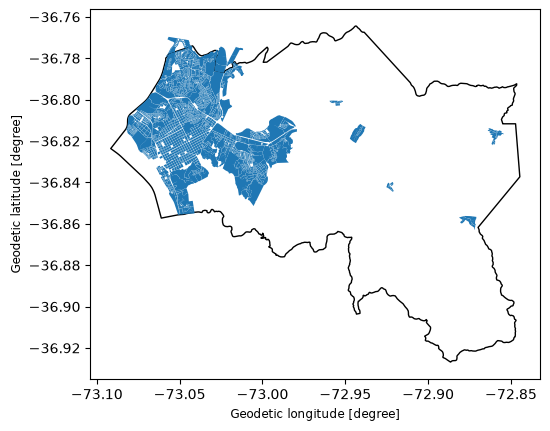

In [86]:
ax = area_gdf.plot(color="none")
blocks_gdf.plot(ax=ax)

In [87]:
# load buildings

if buildings_filename:
    # get points of interest from specified file
    buildings_gdf = load_any(buildings_filename)

    match_indices = buildings_gdf.sindex.query(blocks_gdf.geometry, predicate="intersects")
    buildings_gdf = buildings_gdf.iloc[match_indices[1]]

    print(len(buildings_gdf))
    print(buildings_gdf.head())

c:\Users\secua\Documents\nicolas\accessity\env\Lib\site-packages\h3pandas\h3pandas.py:750: UserWarning: 43 rows did not generate a H3 cell.Consider using a finer resolution.
  warnings.warn(


3548


,cell,geometry
0,8ab2d868045ffff,"POLYGON ((-73.04636 -36.77126, -73.04586 -36.7..."
1,8ab2d868048ffff,"POLYGON ((-73.05108 -36.77119, -73.05058 -36.7..."
2,8ab2d8680497fff,"POLYGON ((-73.05332 -36.77062, -73.05282 -36.7..."
3,8ab2d868049ffff,"POLYGON ((-73.05232 -36.77144, -73.05183 -36.7..."
4,8ab2d86804c7fff,"POLYGON ((-73.04884 -36.77176, -73.04835 -36.7..."


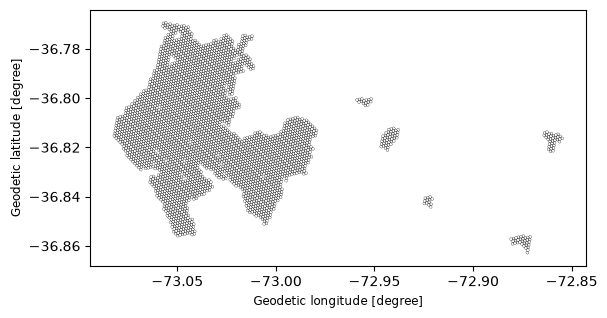

In [88]:
# get all the h3 hexagons from all the blocks with people

hexagons_gdf = blocks_gdf.h3.polyfill_resample(h3_resolution + 1).h3.h3_to_parent_aggregate(h3_resolution)
hexagons_gdf = hexagons_gdf.reset_index(names="cell")
hexagons_gdf = hexagons_gdf[["cell", "geometry"]]

print(len(hexagons_gdf))
hexagons_gdf.plot(color="none", linewidth=0.2)
hexagons_gdf.head()

In [89]:
if pois_filename:
    # get points of interest from specified file
    pois_gdf = load_any(pois_filename)
    if "id" not in pois_gdf.columns:
        raise ValueError("ERROR: specified points of interest file doesn't contain 'id'")
    if "geometry" not in pois_gdf.columns:
        raise ValueError("ERROR: specified points of interest file doesn't contain 'geometry'")
else:
    # get points of interest from osm
    pois_gdf = osm.get_pois(custom_filter=tags)

    pois_gdf = pois_gdf.to_crs(32718)
    pois_gdf.geometry = pois_gdf.geometry.centroid
    pois_gdf = pois_gdf.to_crs(4326)

    pois_gdf = pois_gdf[~pois_gdf["amenity"].isna()]
    pois_gdf = pois_gdf[pois_gdf['amenity'] != 'bench']

    pois_gdf.lon = pois_gdf.geometry.x
    pois_gdf.lat = pois_gdf.geometry.y
    pois_gdf = pois_gdf.rename(columns={"lon": "x", "lat": "y"})

    pois_gdf = pois_gdf[["id", "x", "y", "amenity", "geometry"]]

In [90]:
# # download tiles.geojson from https://openbuildings-public-dot-gweb-research.uw.r.appspot.com/public/tiles.geojson
# building_areas_filename = "tiles.geojson"

# with open(building_areas_filename) as f:
#     geojson = json.load(f)

# building_areas_gdf = gpd.GeoDataFrame.from_features(geojson["features"], crs=4326)
# building_areas_gdf.plot(figsize=(4,4), color="#cccccc", edgecolor="black")

# accessibility

C:\Users\secua\AppData\Local\Temp\ipykernel_36332\1943068682.py:2: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  origins_gdf.geometry = origins_gdf.geometry.centroid


3548


,id,cell,geometry
0,0,8ab2d868045ffff,POINT (-73.04661 -36.77063)
1,1,8ab2d868048ffff,POINT (-73.05133 -36.77056)
2,2,8ab2d8680497fff,POINT (-73.05357 -36.76999)
3,3,8ab2d868049ffff,POINT (-73.05257 -36.77081)
4,4,8ab2d86804c7fff,POINT (-73.04909 -36.77113)


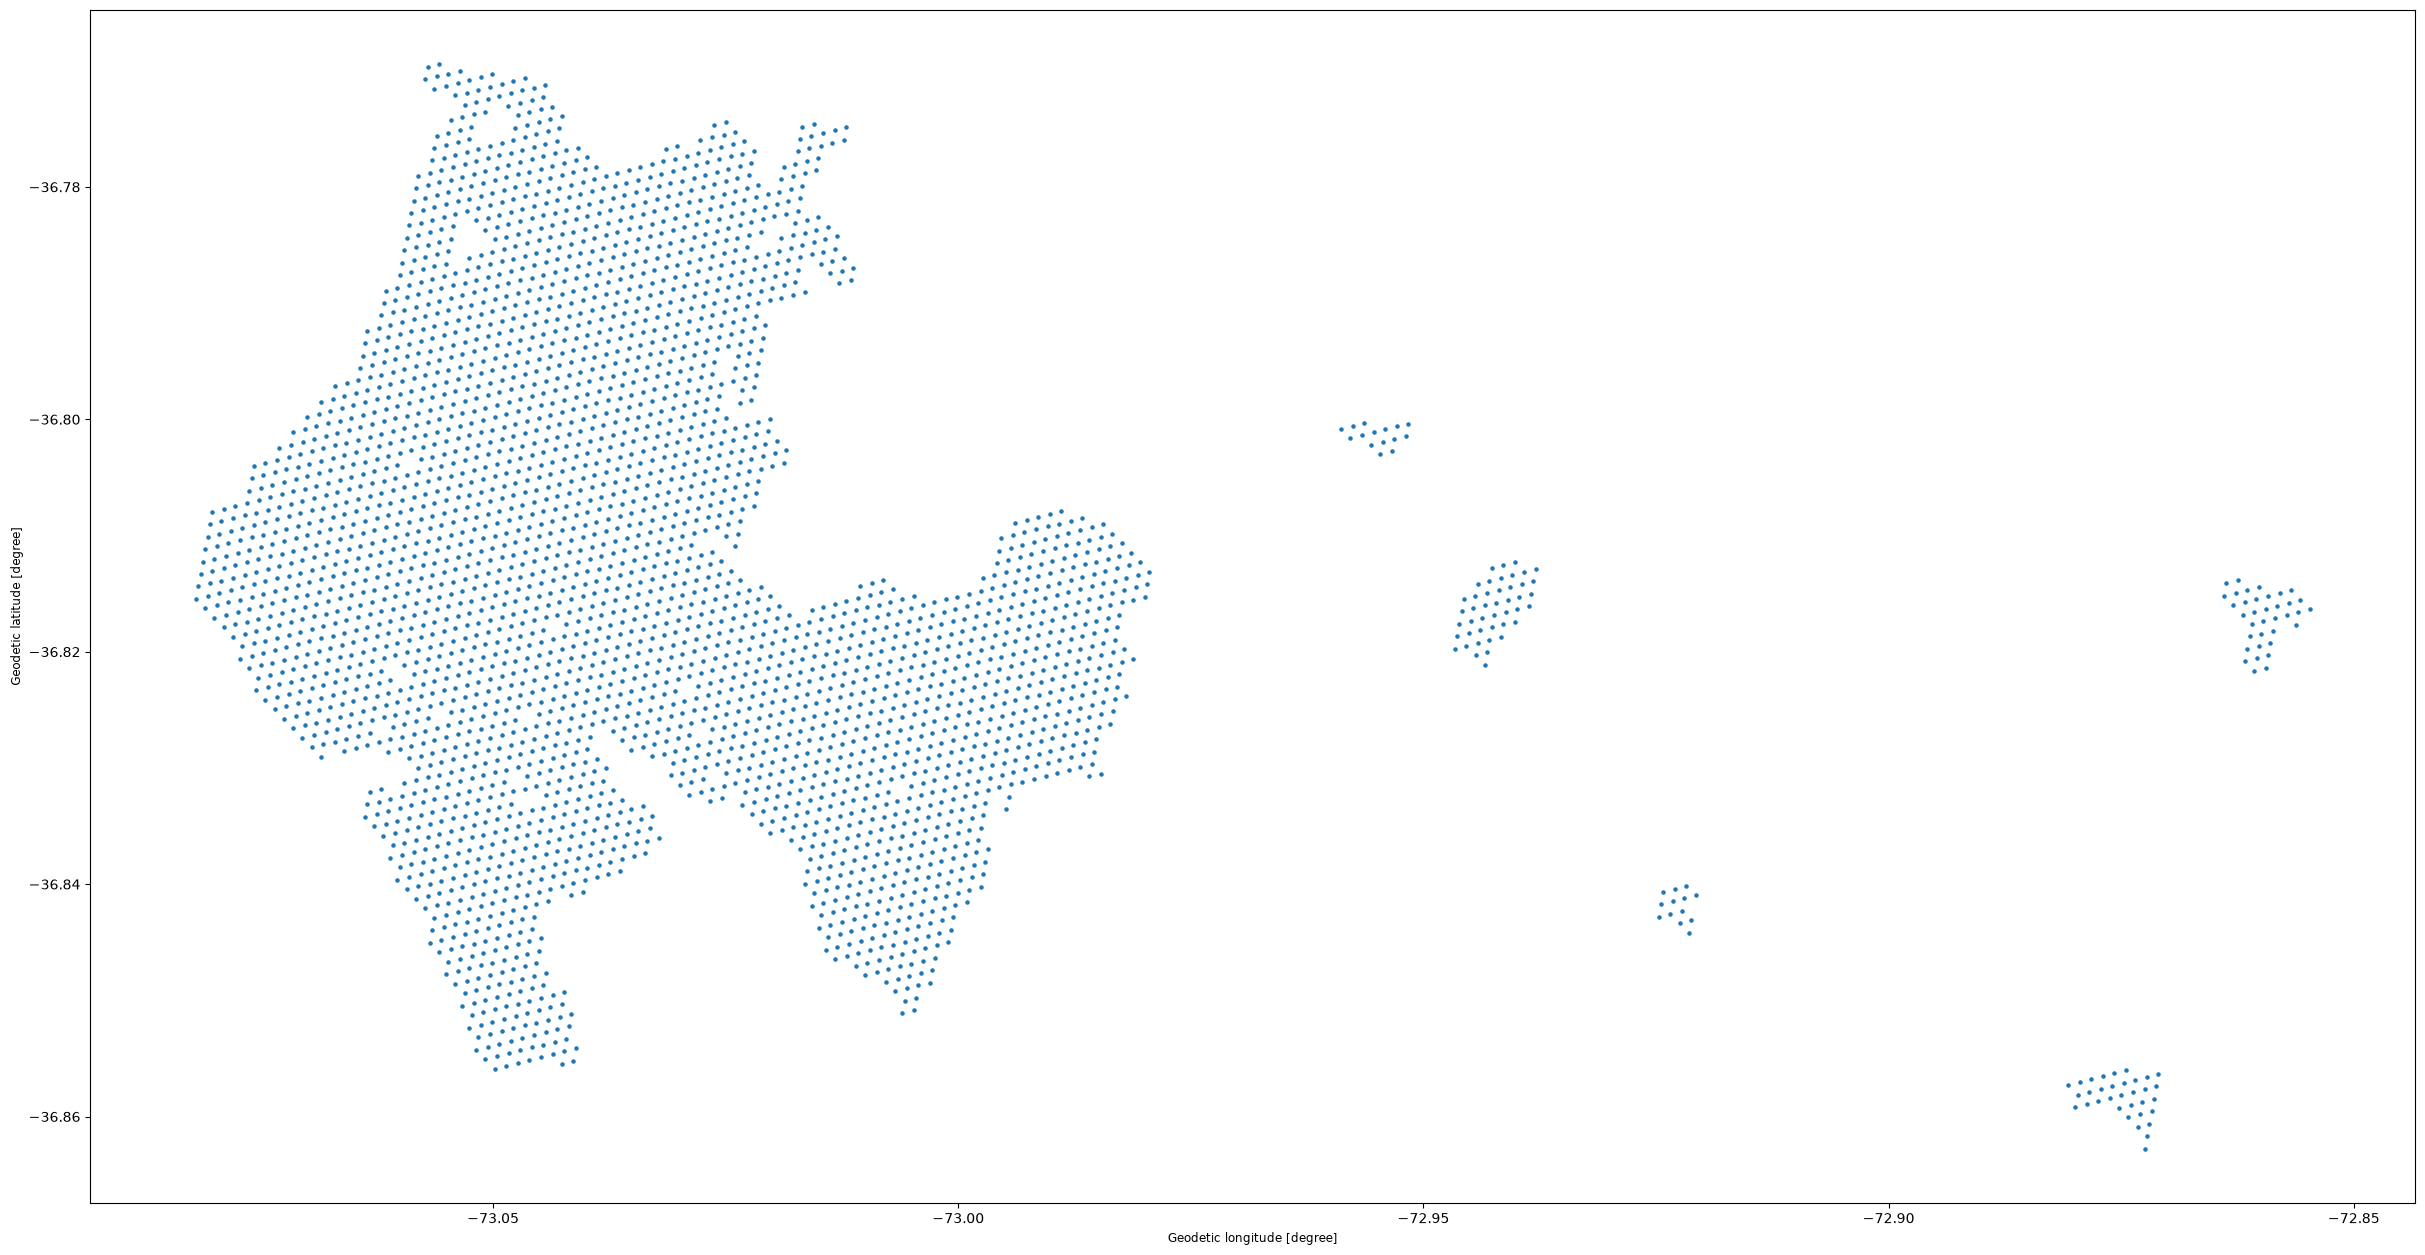

In [91]:
origins_gdf = hexagons_gdf.copy()
origins_gdf.geometry = origins_gdf.geometry.centroid
origins_gdf = origins_gdf.reset_index(names="id")
origins_gdf.plot(figsize=(30,30), markersize=5)
print(len(origins_gdf))
origins_gdf.head()

1609


,id,x,y,amenity,geometry
0,0,-73.049019,-36.825828,pharmacy,POINT (-73.04902 -36.82583)
1,1,-73.058864,-36.789820,pharmacy,POINT (-73.05886 -36.78982)
2,2,-73.049807,-36.826167,pharmacy,POINT (-73.04981 -36.82617)
3,3,-73.049703,-36.828868,pharmacy,POINT (-73.0497 -36.82887)
4,4,-73.049033,-36.826076,pharmacy,POINT (-73.04903 -36.82608)


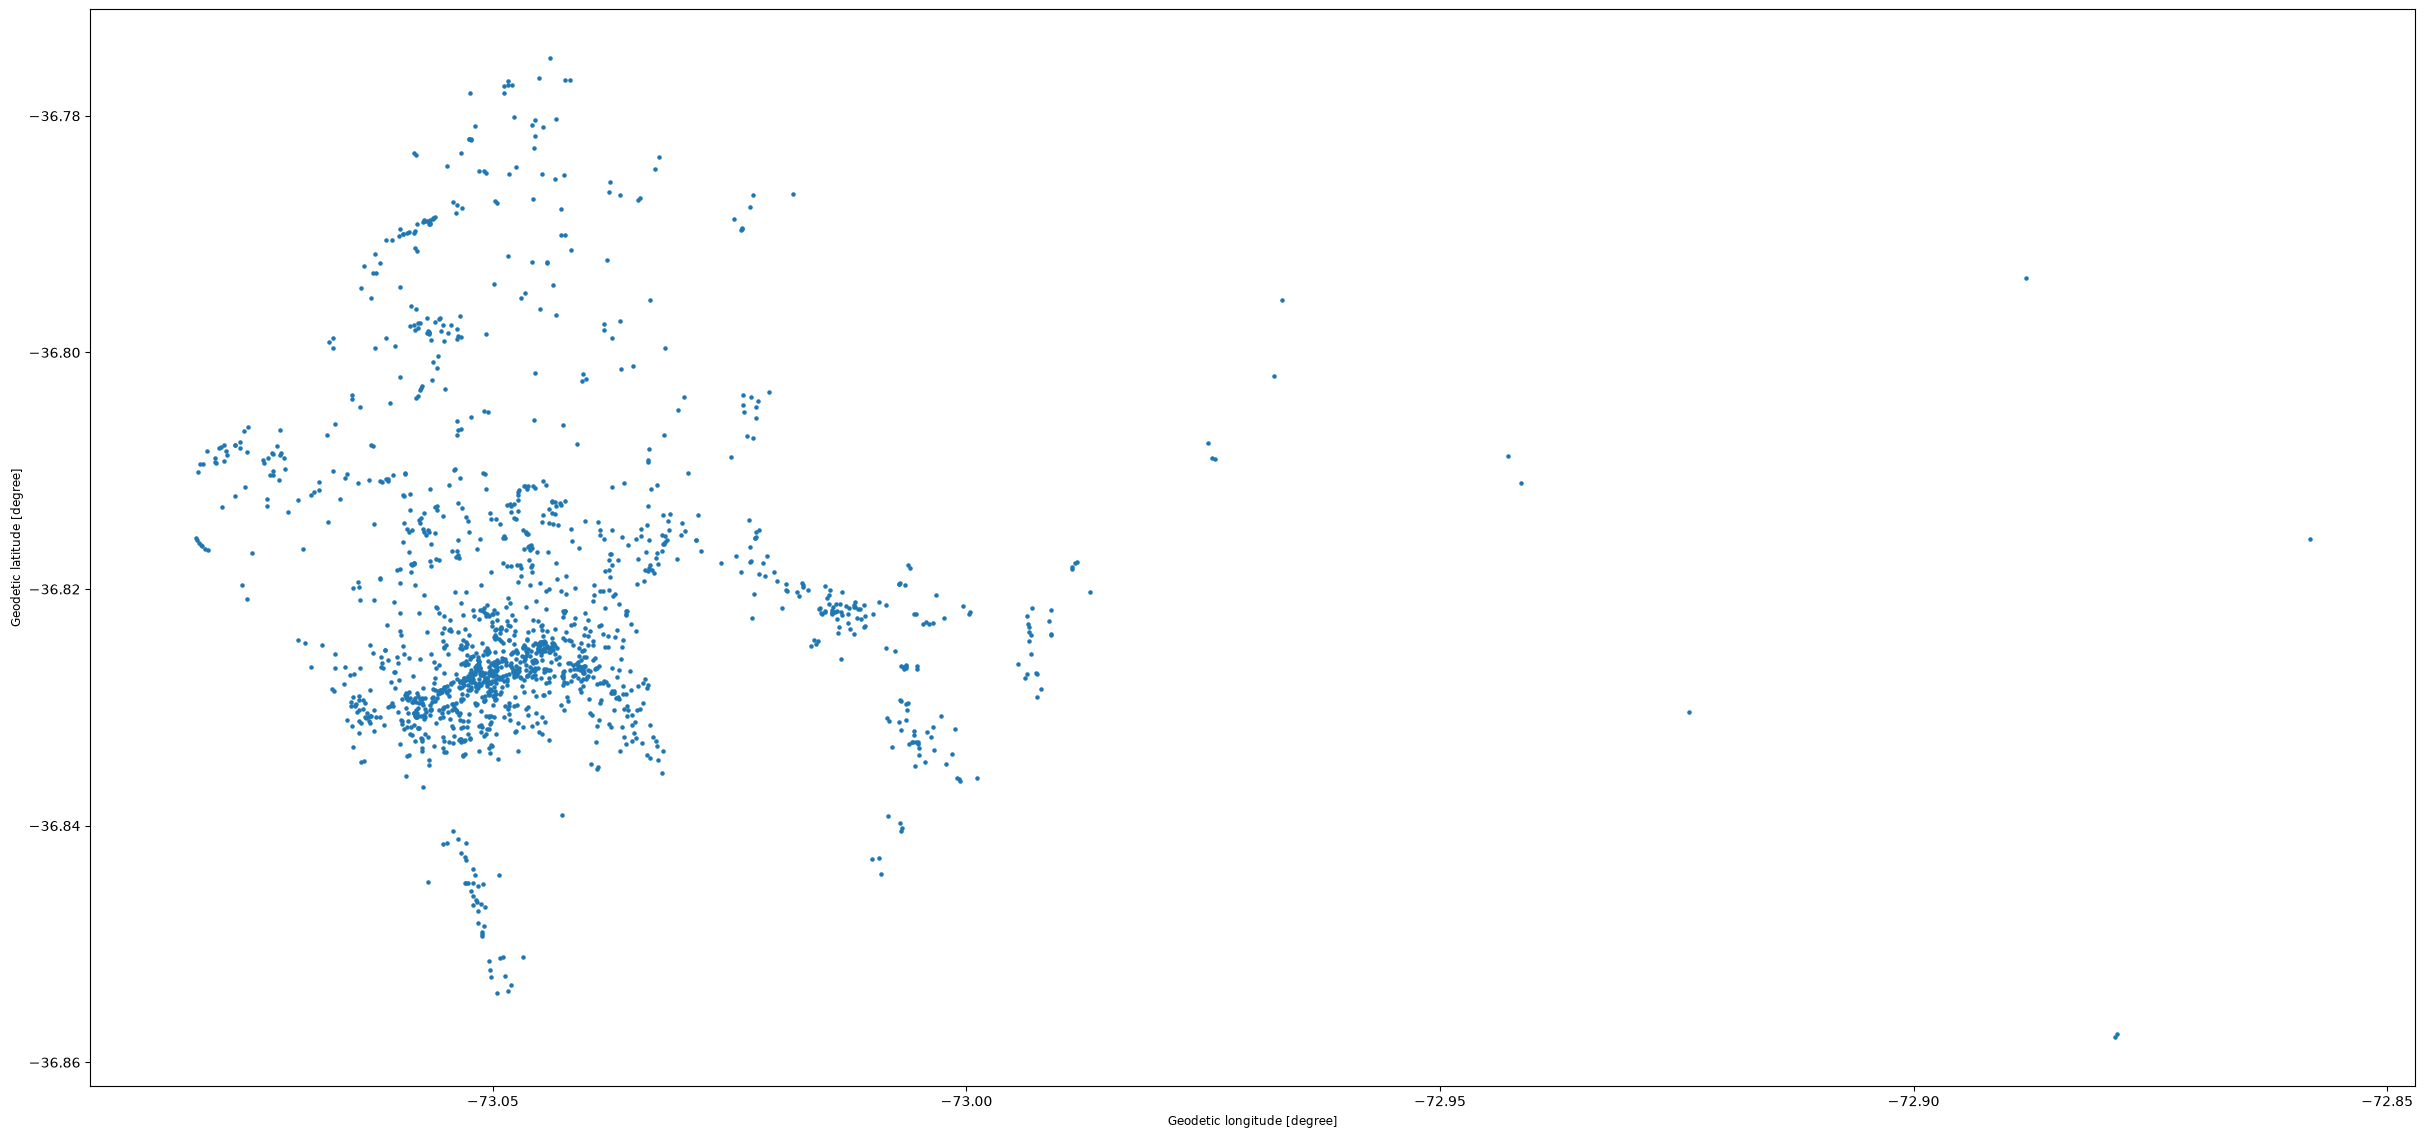

In [92]:
destinations_gdf = pois_gdf
destinations_gdf = destinations_gdf.drop(columns="id", errors="ignore")
destinations_gdf = destinations_gdf.reset_index(drop=True)
destinations_gdf = destinations_gdf.reset_index(names="id")
destinations_gdf.plot(figsize=(30,30), markersize=5)
print(len(destinations_gdf))
destinations_gdf.head()

In [93]:
from pathlib import Path
import shutil
import platformdirs

# 1. Clear any .mapdb cache files in your current working directory
local_mapdbs = list(Path(".").glob("*.mapdb"))
for file in local_mapdbs:
  file.unlink()
  print(f"Deleted local cache file: {file.name}")

# 2. Clear r5py's system/user cache directory
cache_dir = Path(platformdirs.user_cache_dir("r5py"))
if cache_dir.exists():
  shutil.rmtree(cache_dir)
  print(f"Cleared r5py user cache at: {cache_dir}")
else:
  print("User cache directory is already clean.")

User cache directory is already clean.


In [94]:
transport_network = r5py.TransportNetwork(
    osm_pbf=fp_clip,
    gtfs=gtfs
)
transport_network

In [95]:
access_modes
type(access_modes)

list

In [96]:
import datetime

def get_travel_time_matrix(transport_mode=r5py.TransportMode.CAR):
    modes = transport_mode if isinstance(transport_mode, list) else [transport_mode]
    return  r5py.TravelTimeMatrix(
        transport_network=transport_network,
        origins=origins_gdf,
        destinations=destinations_gdf,

        # transport_modes=[r5py.TransportMode.TRANSIT],
        # DO NOT EDIT as this one is called for each item in the user defined transport_modes 
        transport_modes=modes,

        # access_modes=[r5py.TransportMode.WALK],
        access_modes=access_modes,

        # egress_modes=None,
        egress_modes=egress_modes,

        # snap_to_network=False,
        snap_to_network=snap_to_network,

        # departure=datetime.datetime.now(),
        departure=departure,

        # departure_time_window=datetime.timedelta(minutes=10),
        departure_time_window=departure_time_window,

        # percentiles=[50],
        percentiles=percentiles,

        # max_time=datetime.timedelta(hours=2),
        max_time=max_time,

        # max_time_walking=None,
        max_time_walking=max_time_walking,

        # max_time_cycling=None,
        max_time_cycling=max_time_cycling,

        # max_time_driving=None,
        max_time_driving=max_time_driving,

        # speed_walking=3.6,
        speed_walking=speed_walking,

        # speed_cycling=12.0,
        speed_cycling=speed_cycling,

        # max_public_transport_rides=8,
        max_public_transport_rides=max_public_transport_rides,

        # max_bicycle_traffic_stress=3,
        max_bicycle_traffic_stress=max_bicycle_traffic_stress
    )

In [97]:
travel_time_matrices = {}
for mode in transport_modes:
    print(f"computing {mode.value} travel times")
    travel_time_matrices[mode.value] = get_travel_time_matrix(mode)

# show the first mode computed to see an example of matrix
travel_time_matrices[transport_modes[0].value]

computing WALK travel times


,from_id,to_id,travel_time
0,0,0,0.0
1,0,1,55.0
2,0,2,NaN
3,0,3,NaN
4,0,4,NaN
...,...,...,...
5708727,3547,1604,96.0
5708728,3547,1605,90.0
5708729,3547,1606,57.0
5708730,3547,1607,NaN


In [98]:
# to convert the list of pairs into a matrix crossing each origin with destination uncomment the next line 

# travel_time_matrices[modes[0]].pivot(index="from_id", columns="to_id", values="travel_time")

In [99]:
osm = pyrosm.OSM(osm_filename, bounding_box=area)
walk_nodes, walk_edges = osm.get_network(network_type="walk", nodes=True)

match_indices = walk_edges.sindex.query(area, predicate="intersects")
walk_edges = walk_edges.iloc[match_indices]

node_ids = set(walk_edges['u']).union(set(walk_edges['v']))
walk_nodes = walk_nodes[walk_nodes['id'].isin(node_ids)]

walk_nodes = walk_nodes.rename(columns={'lon': 'x', 'lat': 'y'})
G = osm.to_graph(walk_nodes, walk_edges, graph_type="networkx", simplify=True)

walk_nodes, walk_edges = ox.graph_to_gdfs(G)

In [100]:
matrix_gdfs = {}

for key, travel_time_matrix in travel_time_matrices.items():
    matrix_gdfs[key] = travel_time_matrix.copy()
    matrix_gdfs[key] = matrix_gdfs[key].merge(origins_gdf, "outer", left_on="from_id", right_on="id")
    matrix_gdfs[key] = matrix_gdfs[key].drop(columns="id")
    matrix_gdfs[key] = matrix_gdfs[key].merge(destinations_gdf[["id", "amenity"]], "outer", left_on="to_id", right_on="id")
    matrix_gdfs[key] = matrix_gdfs[key].drop(columns="id")
    matrix_gdfs[key] = matrix_gdfs[key][["from_id", "to_id", "cell", "amenity", "travel_time", "geometry"]]
    matrix_gdfs[key] = gpd.GeoDataFrame(matrix_gdfs[key], geometry="geometry", crs=4326)

matrix_gdfs[key]

,from_id,to_id,cell,amenity,travel_time,geometry
0,0,0,8ab2d868045ffff,pharmacy,0.0,POINT (-73.04661 -36.77063)
1,1,0,8ab2d868048ffff,pharmacy,NaN,POINT (-73.05133 -36.77056)
2,2,0,8ab2d8680497fff,pharmacy,NaN,POINT (-73.05357 -36.76999)
3,3,0,8ab2d868049ffff,pharmacy,NaN,POINT (-73.05257 -36.77081)
4,4,0,8ab2d86804c7fff,pharmacy,NaN,POINT (-73.04909 -36.77113)
...,...,...,...,...,...,...
5708727,3543,1608,8ab2dbd35d57fff,parking,NaN,POINT (-73.05157 -36.85316)
5708728,3544,1608,8ab2dbd35d5ffff,parking,79.0,POINT (-73.05058 -36.85398)
5708729,3545,1608,8ab2dbd35d67fff,parking,76.0,POINT (-73.05008 -36.85184)
5708730,3546,1608,8ab2dbd35d6ffff,parking,79.0,POINT (-73.04908 -36.85266)


In [101]:
filter_amenity = "hospital"

hex_matrix_gdfs = {}
for key, matrix_gdf in matrix_gdfs.items():
    hex_matrix_gdfs[key] = matrix_gdf.copy()
    hex_matrix_gdfs[key] = hex_matrix_gdfs[key][hex_matrix_gdfs[key].amenity == filter_amenity].groupby("cell").agg({
        "amenity": "first",
        "travel_time": "min" # AGREACIÓN DEL MÍNIMO (APLICAR FUNCIÓN ACUMULATIVA)
        })
    geoms = hexagons_gdf.set_index("cell").geometry.loc[hex_matrix_gdfs[key].index]
    hex_matrix_gdfs[key] = gpd.GeoDataFrame(hex_matrix_gdfs[key], geometry=geoms, crs=4326)


hex_matrix_gdfs[key]

,amenity,travel_time,geometry
cell,,,
8ab2d868045ffff,hospital,102.0,"POLYGON ((-73.04636 -36.77126, -73.04586 -36.7..."
8ab2d868048ffff,hospital,NaN,"POLYGON ((-73.05108 -36.77119, -73.05058 -36.7..."
8ab2d8680497fff,hospital,NaN,"POLYGON ((-73.05332 -36.77062, -73.05282 -36.7..."
8ab2d868049ffff,hospital,NaN,"POLYGON ((-73.05232 -36.77144, -73.05183 -36.7..."
8ab2d86804c7fff,hospital,103.0,"POLYGON ((-73.04884 -36.77176, -73.04835 -36.7..."
...,...,...,...
8ab2dbd35d57fff,hospital,NaN,"POLYGON ((-73.05132 -36.85379, -73.05082 -36.8..."
8ab2dbd35d5ffff,hospital,73.0,"POLYGON ((-73.05033 -36.85461, -73.04983 -36.8..."
8ab2dbd35d67fff,hospital,70.0,"POLYGON ((-73.04983 -36.85247, -73.04933 -36.8..."


In [102]:
for key in matrix_gdfs.keys():
    hex_matrix_gdfs[key].travel_time = hex_matrix_gdfs[key].travel_time.fillna(np.inf)

hex_matrix_gdfs["WALK"][hex_matrix_gdfs["WALK"].travel_time.isna()]

,amenity,travel_time,geometry
cell,,,


In [105]:
# load network to draw edges
osm = pyrosm.OSM(osm_filename, bounding_box=area)
nodes, edges = osm.get_network(network_type="DRIVE", nodes=True)

# spatial index clip
match_indices = edges.sindex.query(area, predicate="intersects")
edges = edges.iloc[match_indices]

# filter nodes referenced by edges
node_ids = set(edges['u']).union(set(edges['v']))
nodes = nodes[nodes['id'].isin(node_ids)]

# build networkx graph
nodes = nodes.rename(columns={'lon': 'x', 'lat': 'y'})
G = osm.to_graph(nodes, edges, graph_type="networkx", simplify=True)

# extract simplified nodes and edges gdfs
nodes, edges = ox.graph_to_gdfs(G)

Reading chile-latest.osm.pbf:   0%|          | 0.00/350M [00:00<?, ?B/s]        

(-36.86338370266274, -36.76879662148102)

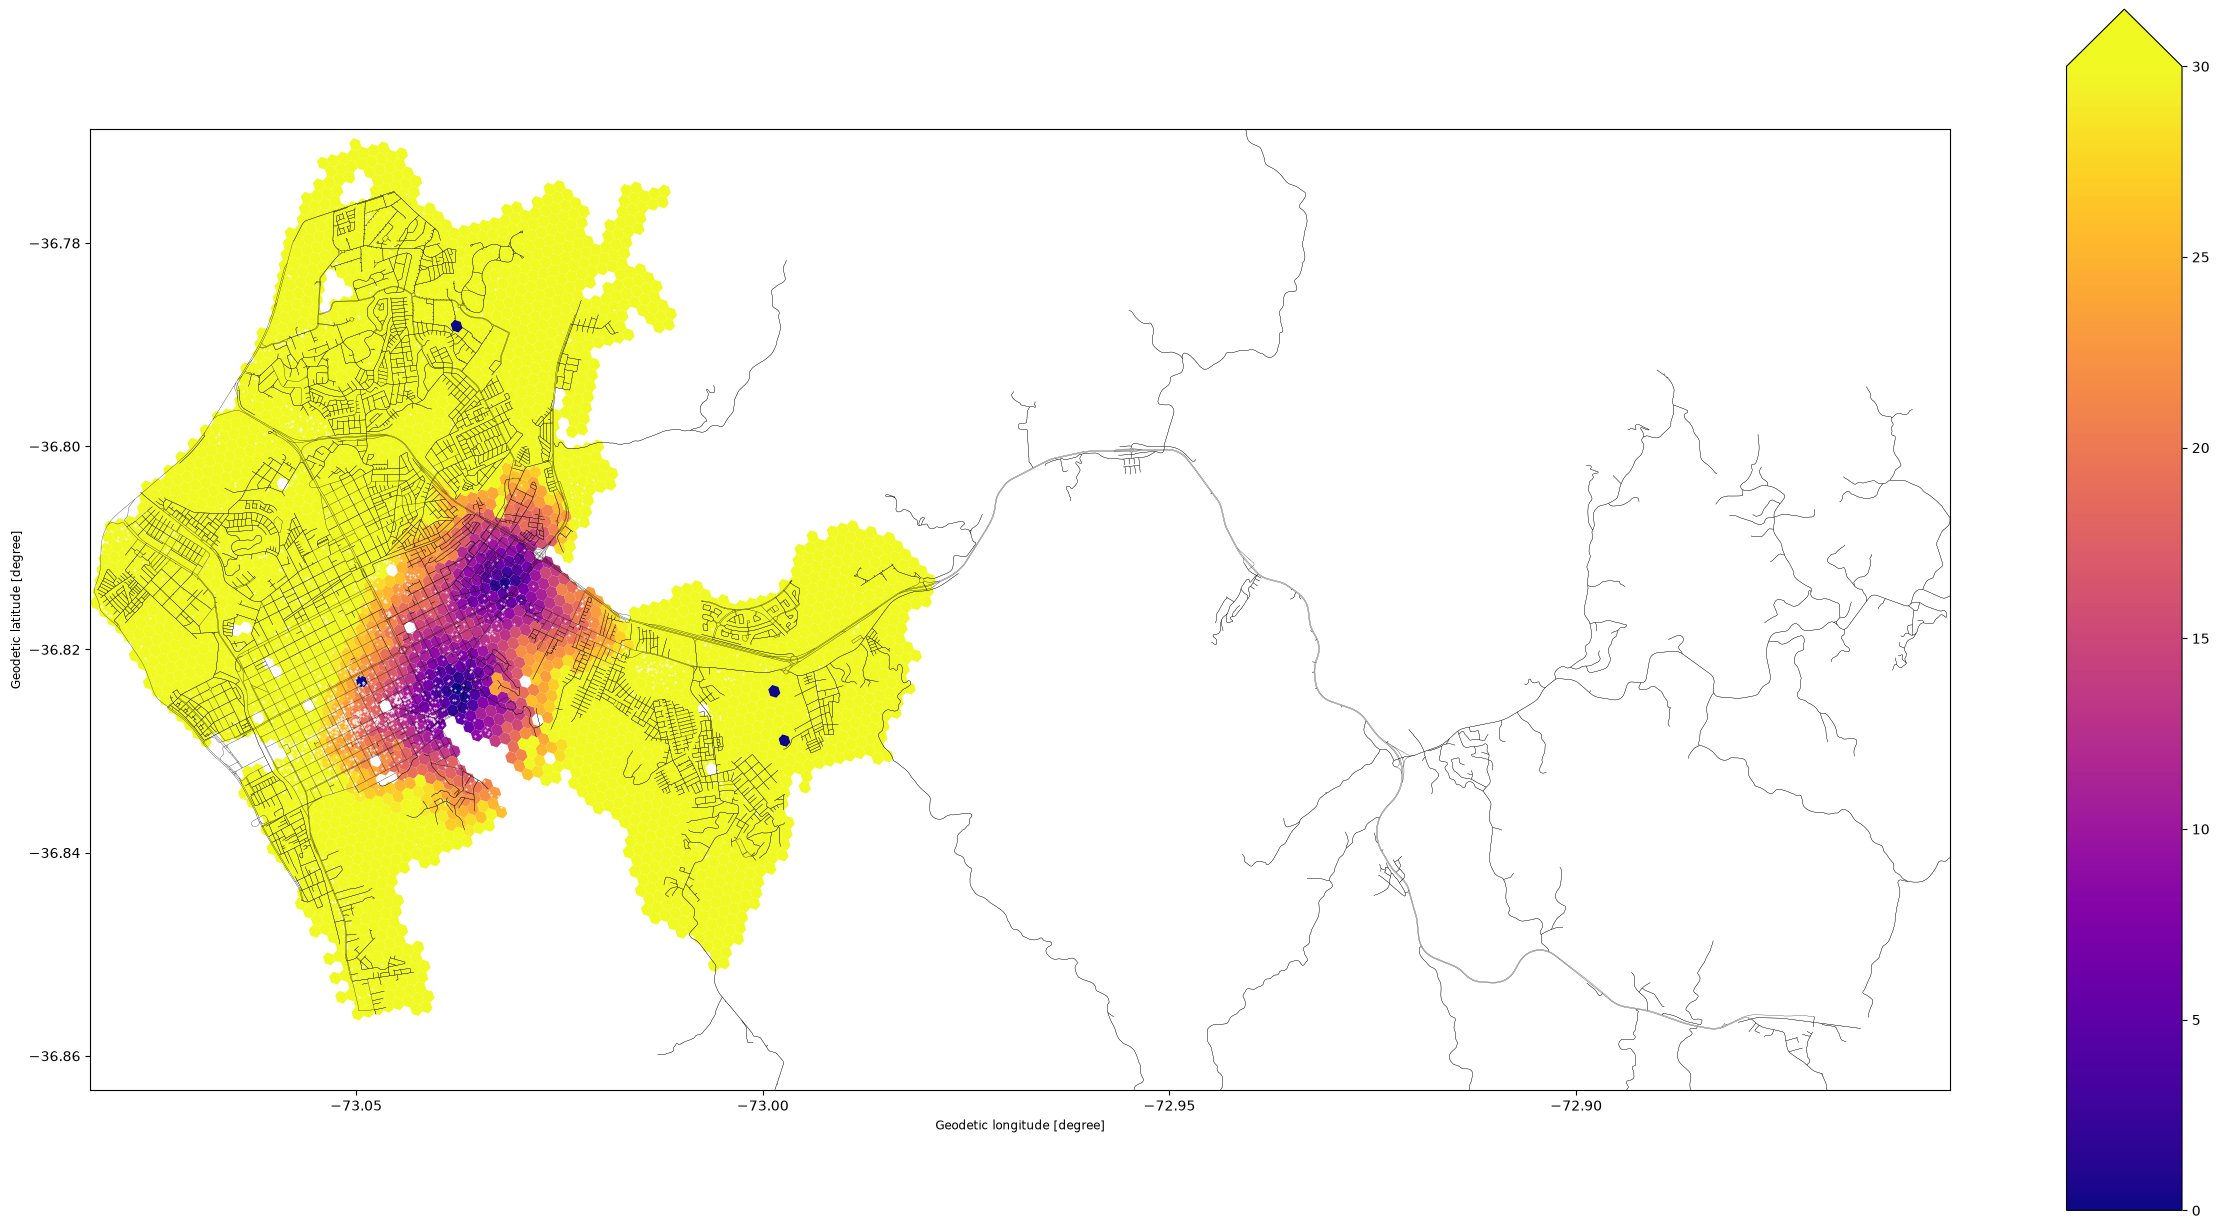

In [106]:
# modes = "WALK" | "CAR" | "BUS"
mode = "WALK"
hex_matrix_gdf = hex_matrix_gdfs[mode]

ax = hex_matrix_gdf.plot(figsize=(30, 30), column="travel_time", markersize=100, cmap="plasma", vmin=0, vmax=30, legend=True)
# hex_matrix_gdf[hex_matrix_gdf.travel_time.isna()].plot(ax=ax, color="magenta")

edges.plot(ax=ax, linewidth=0.2, color="black")
destinations_gdf.plot(ax=ax, markersize=0.2, color="white")

x1, y1, x2, y2 = hex_matrix_gdf[~hex_matrix_gdf.travel_time.isna()].total_bounds
ax.set_xlim(x1, x2)
ax.set_ylim(y1, y2)

In [107]:
# modes = "WALK" | "CAR" | "BUS"
mode = "CAR"
hex_matrix_gdf = hex_matrix_gdfs[mode]

ax = hex_matrix_gdf.plot(figsize=(30, 30), column="travel_time", markersize=100, cmap="plasma", vmin=0, vmax=60, legend=True)
# hex_matrix_gdf[hex_matrix_gdf.travel_time.isna()].plot(ax=ax, color="magenta")

edges.plot(ax=ax, linewidth=0.2, color="black")
destinations_gdf.plot(ax=ax, markersize=0.2, color="white")

x1, y1, x2, y2 = hex_matrix_gdf[~hex_matrix_gdf.travel_time.isna()].total_bounds
ax.set_xlim(x1, x2)
ax.set_ylim(y1, y2)

KeyError: 'CAR'

(-36.8797305874022, -36.76879662148102)

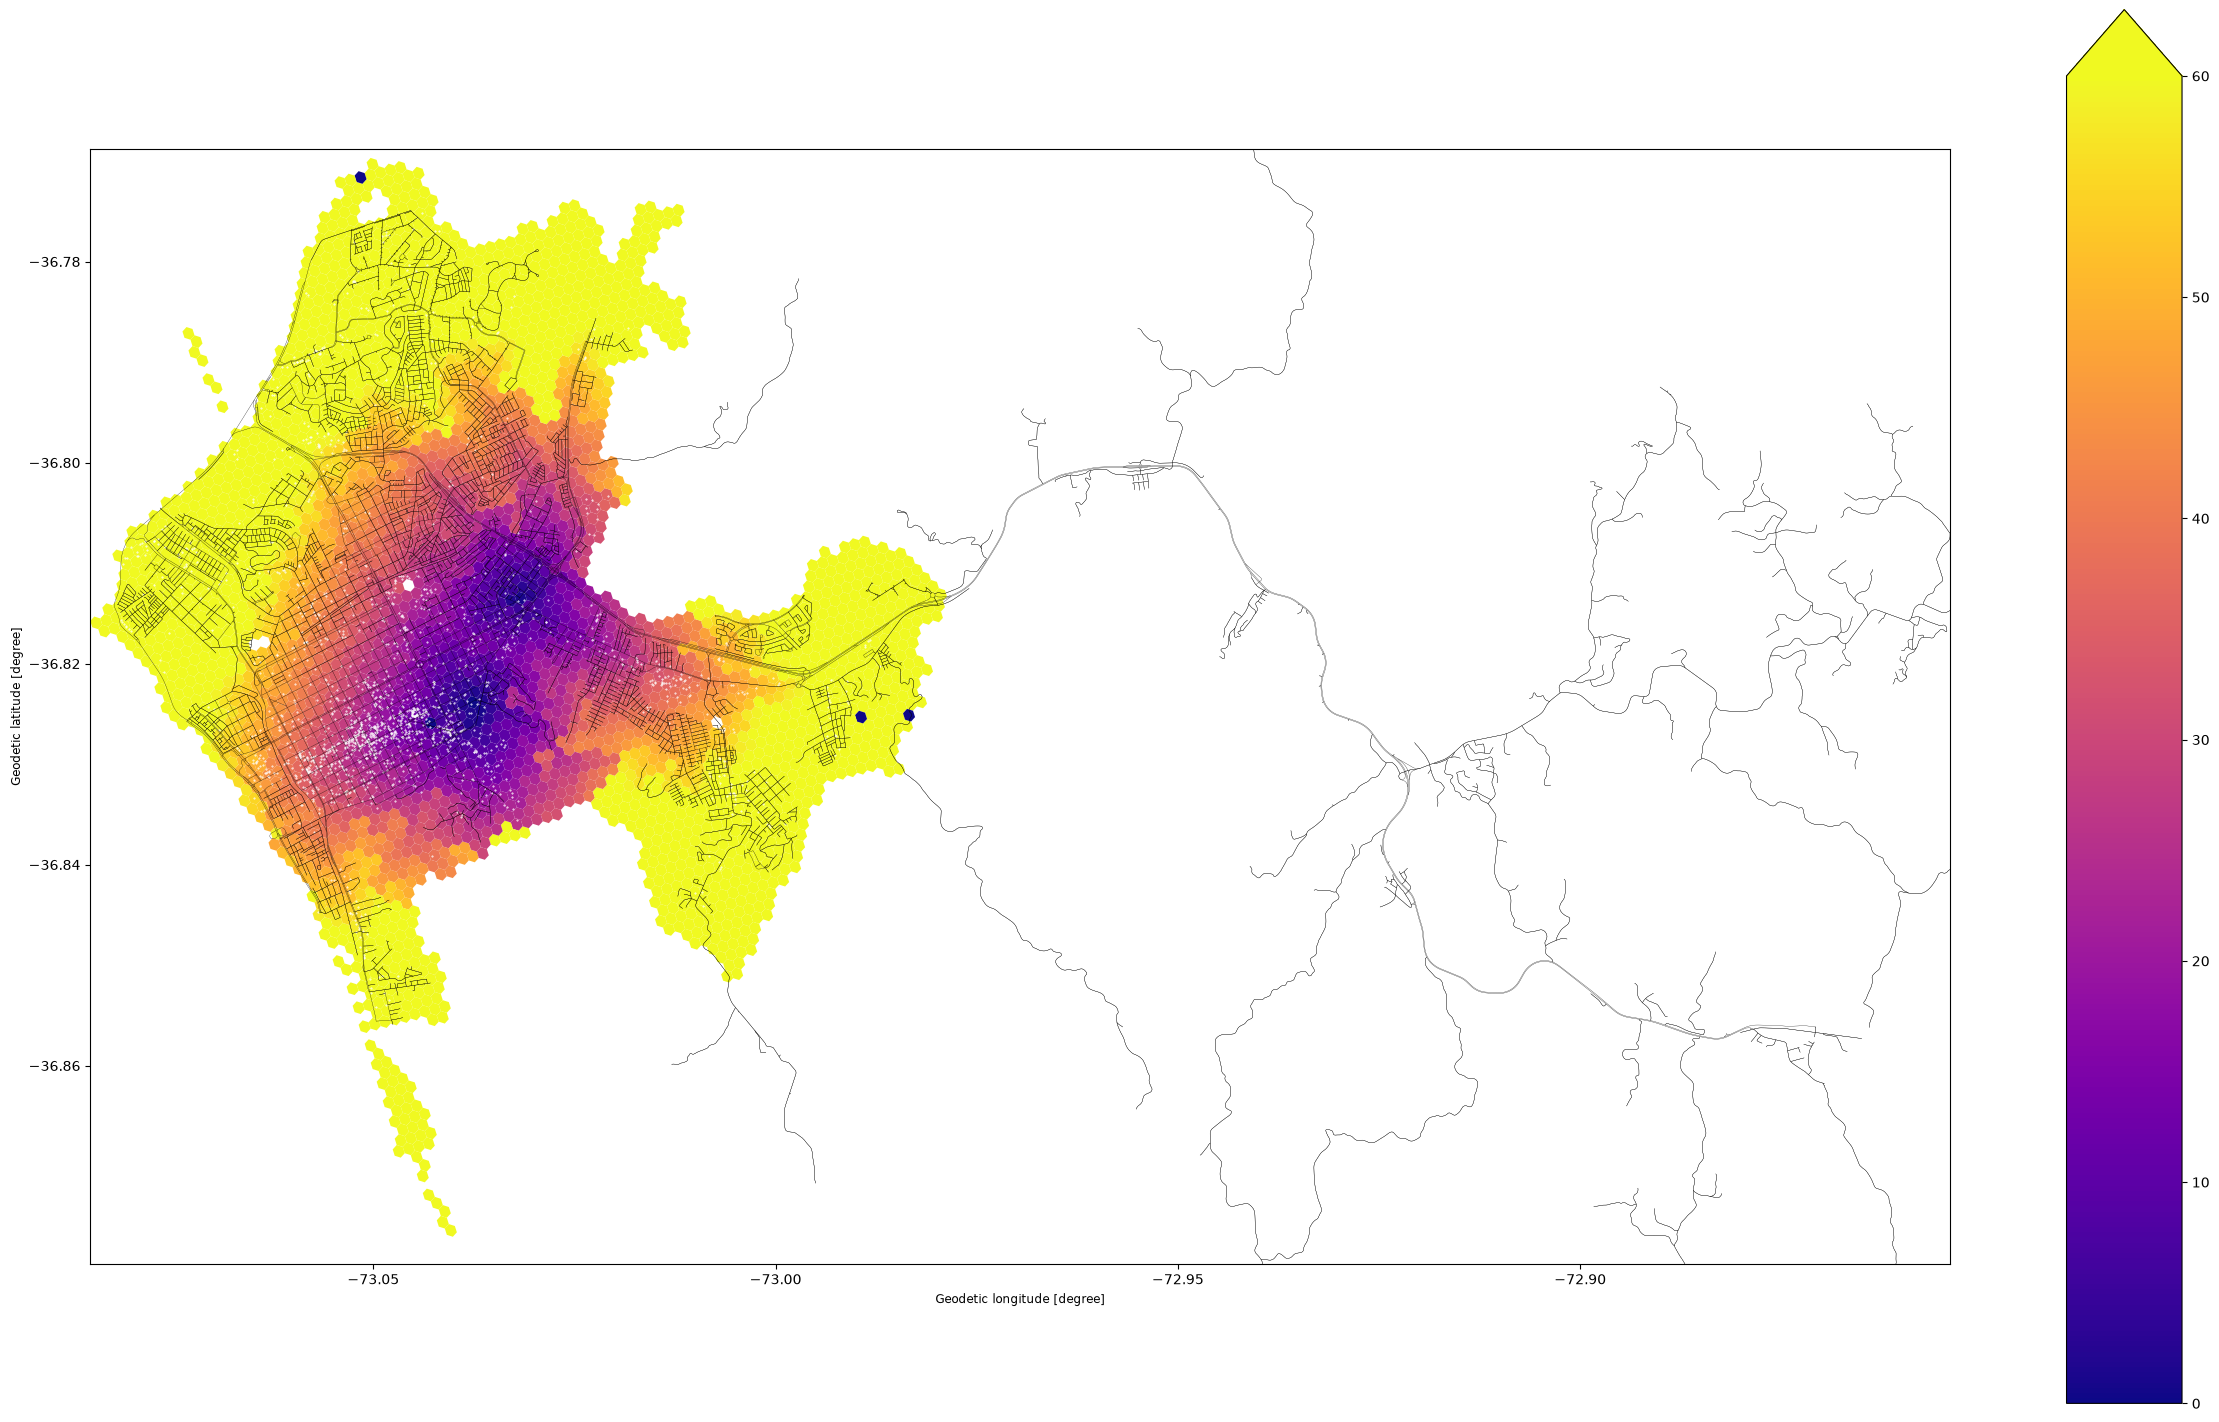

In [ ]:
# modes = "WALK" | "CAR" | "BUS"
mode = "BUS"
hex_matrix_gdf = hex_matrix_gdfs[mode]

ax = hex_matrix_gdf.plot(figsize=(30, 30), column="travel_time", markersize=100, cmap="plasma", vmin=0, vmax=60, legend=True)
# hex_matrix_gdf[hex_matrix_gdf.travel_time.isna()].plot(ax=ax, color="magenta")

edges.plot(ax=ax, linewidth=0.2, color="black")
destinations_gdf.plot(ax=ax, markersize=0.2, color="white")

x1, y1, x2, y2 = hex_matrix_gdf[~hex_matrix_gdf.travel_time.isna()].total_bounds
ax.set_xlim(x1, x2)
ax.set_ylim(y1, y2)

In [ ]:
tmp = matrix_gdfs[key][["from_id", "to_id", "travel_time"]].copy()
tmp

,from_id,to_id,travel_time
0,0,0,0.0
1,1,0,NaN
2,2,0,NaN
3,3,0,NaN
4,4,0,NaN
...,...,...,...
6040181,3749,1608,NaN
6040182,3750,1608,79.0
6040183,3751,1608,76.0
6040184,3752,1608,79.0


In [118]:
key = "WALK"
threshold_minutes = 120
filter_amenity = ""

matrix_df = matrix_gdfs[key][["from_id", "to_id", "travel_time"]].copy()

# filter the pairs inside time threshold
# valid_trips = matrix_df[matrix_df.travel_time <= threshold_minutes]

matrix_df["weight"] = 1.0
matrix_df.loc[matrix_df.travel_time.isna(), "weight"] = 0.0
matrix_df.loc[matrix_df.travel_time > threshold_minutes, "weight"] = 0.0

# merge the filtered trips with destinations
merged_df = matrix_df.merge(
    destinations_gdf, left_on="to_id", right_on="id"
)

if filter_amenity:
    merged_df.loc[merged_df.amenity != filter_amenity, "weight"] = 0.0
    # merged_df.loc[(merged_df.amenity != filter_amenity) | (merged_df.travel_time <= threshold_minutes), "weight"] = 0.0
    # merged_df = merged_df.loc[merged_df.amenity == filter_amenity]

accessibility_scores = (
    merged_df.groupby("from_id")["weight"].sum().reset_index() # sum of weights by default
)

accessibility_scores.rename(
    columns={"weight": "score"}, inplace=True
)

# accessibility_scores.score /= accessibility_scores.score.max()

print(accessibility_scores.score.describe())
print(accessibility_scores.score.quantile(0.95))
accessibility_scores

count    3548.000000
mean     1334.224352
std       396.391266
min         1.000000
25%      1308.000000
50%      1499.000000
75%      1575.000000
max      1597.000000
Name: score, dtype: float64
1594.0


,from_id,score
0,0,499.0
1,1,437.0
2,2,399.0
3,3,444.0
4,4,612.0
...,...,...
3543,3543,403.0
3544,3544,1333.0
3545,3545,1378.0
3546,3546,1346.0


(-36.9268099, -36.7644238)

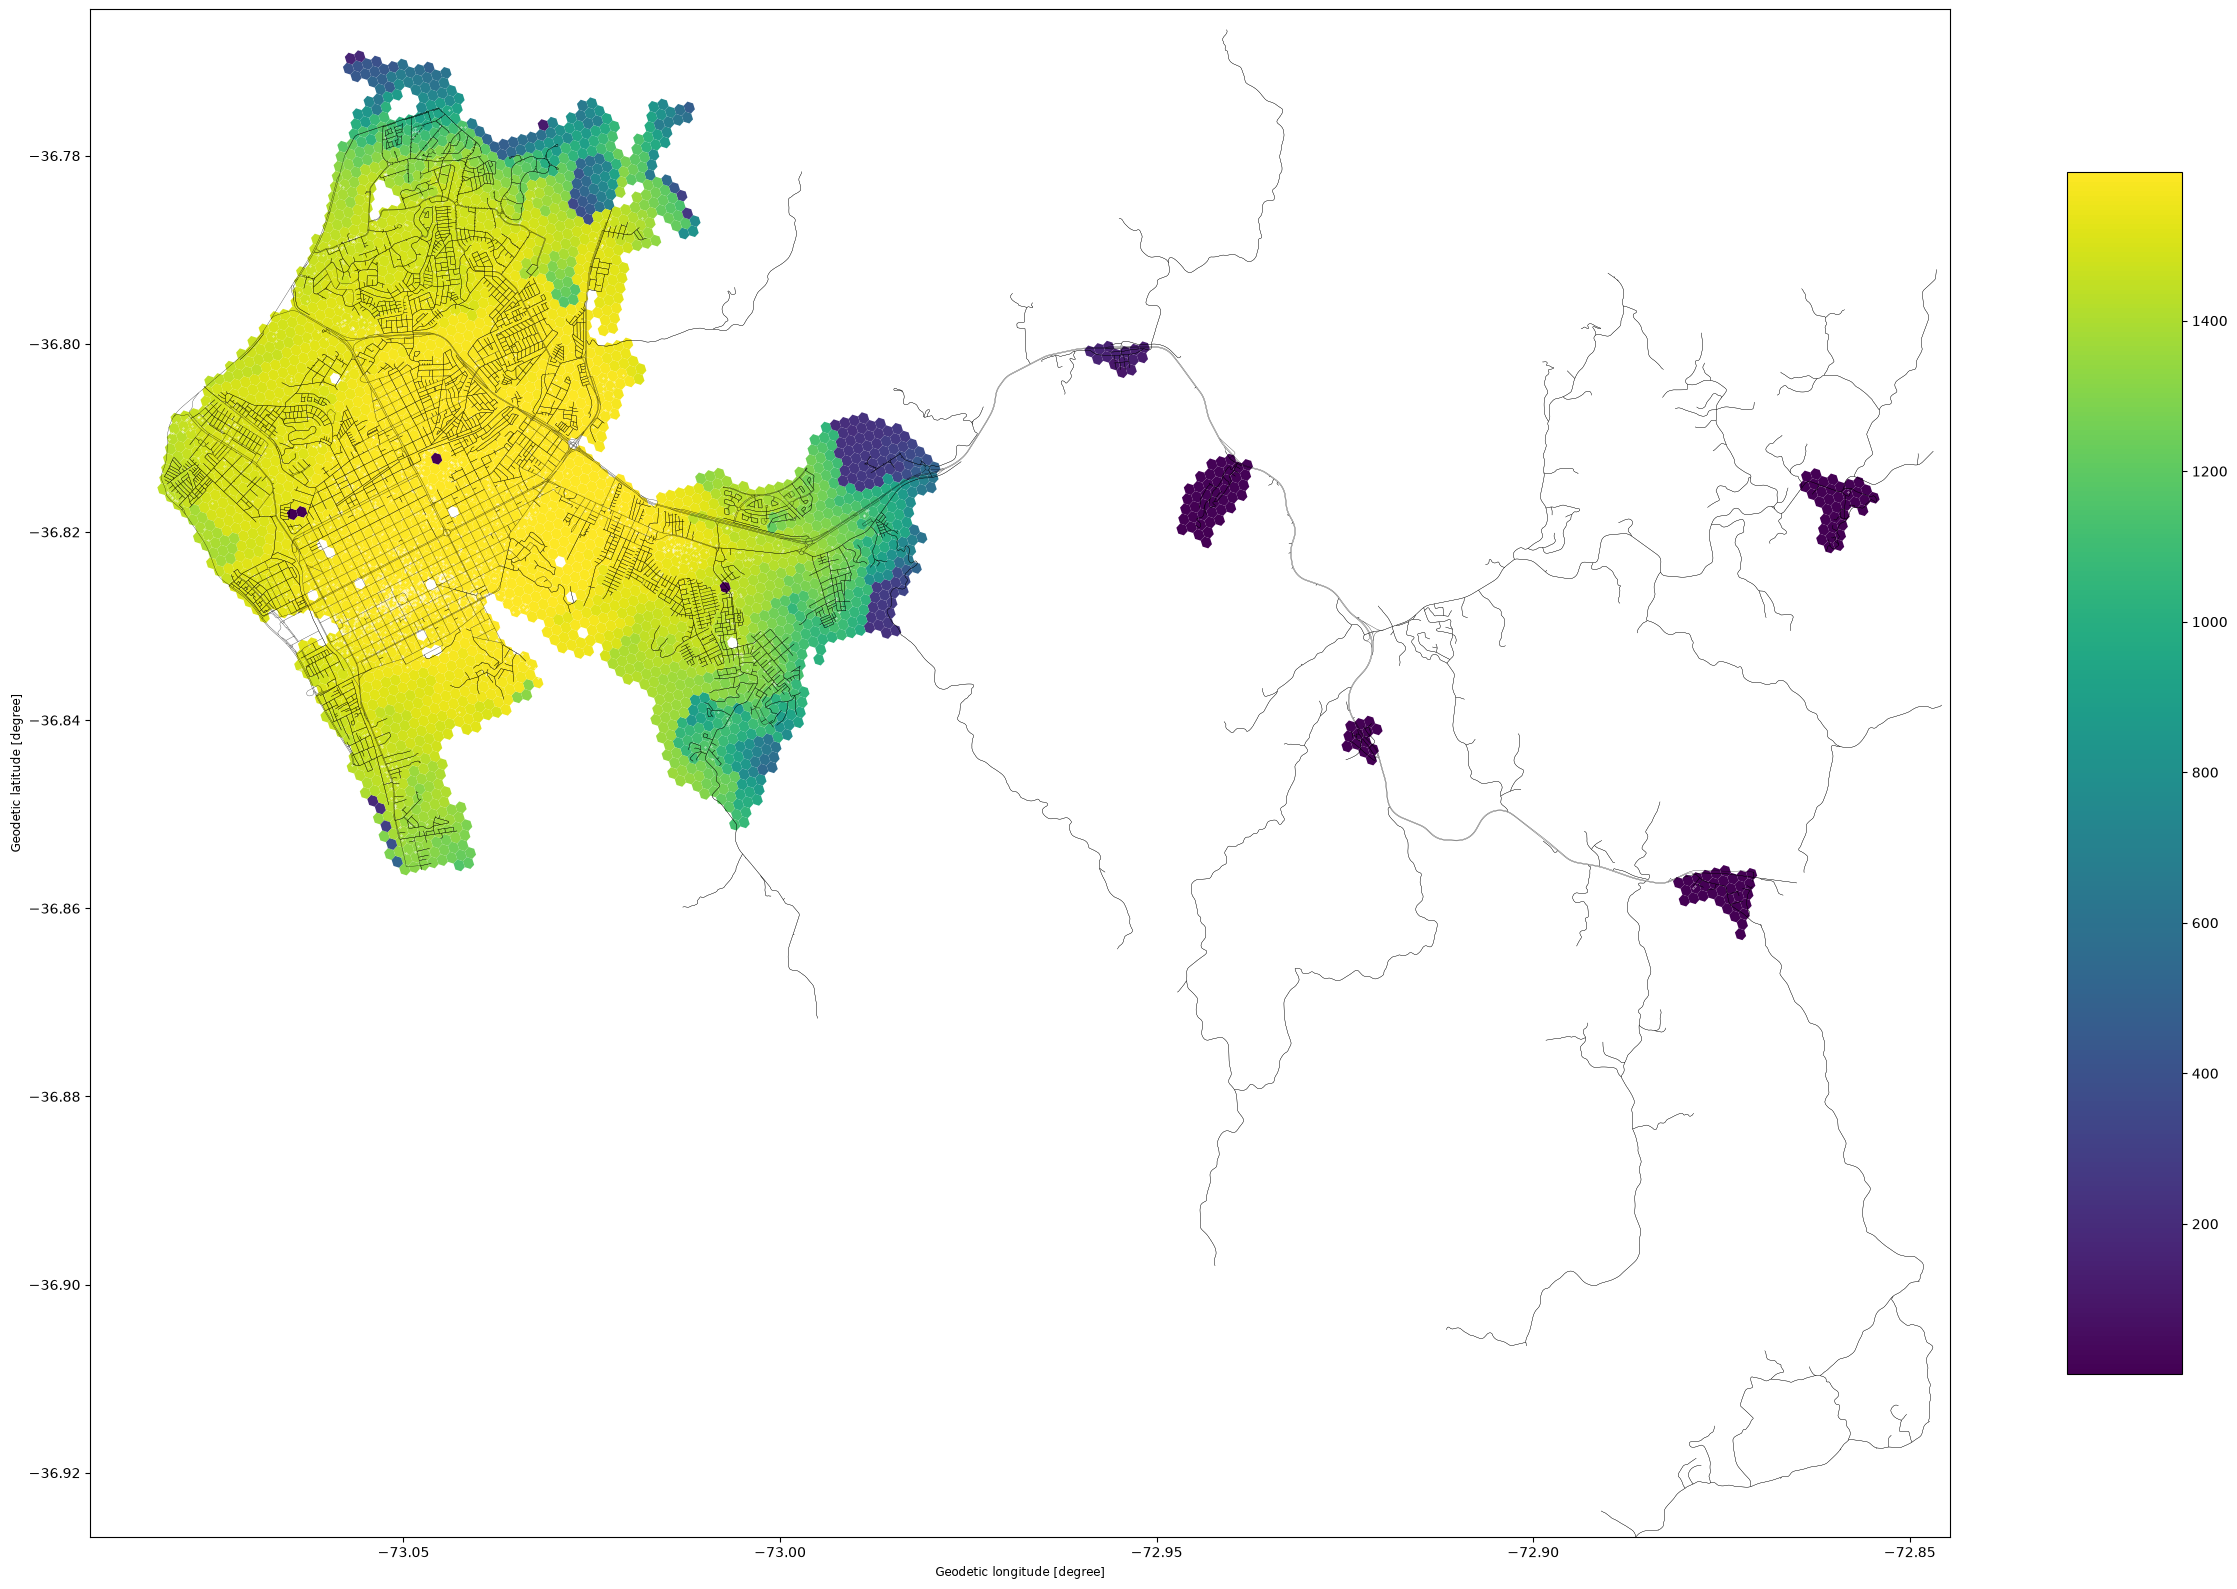

In [119]:
accessibility_hexagons = accessibility_scores.merge(hexagons_gdf, "inner", left_on="from_id", right_index=True)
accessibility_hexagons = gpd.GeoDataFrame(accessibility_hexagons, geometry="geometry", crs=4326)

ax = accessibility_hexagons.plot(figsize=(30,30), column="score", cmap="viridis", legend=True)

# blocks_gdf.plot(ax=ax)
edges.plot(ax=ax, linewidth=0.2, color="black")

if filter_amenity:
    destinations_gdf[destinations_gdf.amenity == filter_amenity].plot(ax=ax, markersize=5, color="white")
else:
    destinations_gdf.plot(ax=ax, markersize=0.1, color="white")

x1, y1, x2, y2 = area_gdf.total_bounds
ax.set_xlim(x1, x2)
ax.set_ylim(y1, y2)

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

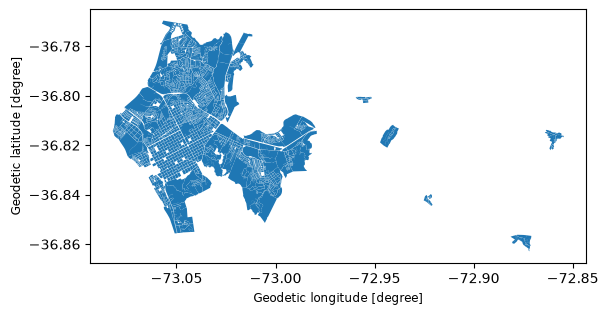

In [110]:
blocks_gdf.plot()

<Axes: >

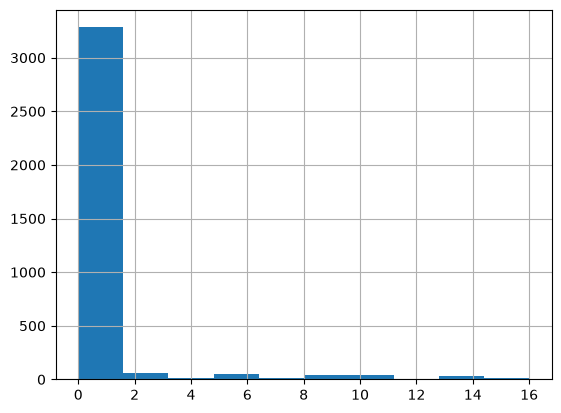

In [111]:
accessibility_hexagons.score.hist(bins=10)

---

In [112]:
# itinerary = r5py.DetailedItineraries(
#     transport_network=transport_network,
#     origins=origins_gdf,
#     destinations=destinations_gdf.loc[destinations_gdf.id == 2],
#     transport_modes=[r5py.TransportMode.CAR]
# )
# itineraries_gdf = itinerary.to_geodataframe()
# print(itineraries_gdf)

In [113]:
# hex_travel_times = results_gdf.groupby("cell")["travel_time"].min().reset_index()
# hex_travel_times

In [114]:
# hexagon_travel_times = matching_hexagons_gdf[["id", "cell", "geometry"]]
# hexagon_travel_times = hexagon_travel_times.merge(hex_travel_times, "right", "cell")
# hexagon_travel_times = hexagon_travel_times.set_geometry("geometry")
# hexagon_travel_times

In [115]:
# ax = hexagon_travel_times.plot(figsize=(30,30), column="travel_time")
# # destinations_gdf.plot(ax=ax, color="red")